# Name(s): Sanjay Rajjan, Shreya Karthikeyan

**Academic Integrity Notice**

This notebook is a graded homework assignment. Using AI to solve homework problems is against course policy.

You may **NOT**:
- Ask an AI system to generate or fill in answers or code for this assignment
- Upload this notebook to an AI system and ask that it be completed
- Copy/paste questions from this assignment into an AI system to generate answers
- Use code auto-complete within your code editor to generate answers

You MUST:
- Turn off code auto-complete or use an editor that does not have it (such a Jupyter Notebook)

You MAY:
- Use the internet (not an LLM) to find general examples of how to do things with Python or Pandas
- Use the internet (not an LLM) for help interpreting error messages
- Come to the TA or the Professor's office hours for coding help or other questions

Students who submit AI-generated solutions as their own work will be subject to academic misconduct procedures.

By continuing the assignment, you acknowledge and agree to these academic integrity rules.


# Assignment 5: Clustering

In this assignment we'll be looking at three popular types of clustering algorithms -- K-means clustering, Density-based clustering, and Hierarchical clustering. We'll also look at some measures of cluster quality like cohesion, separation and silhoutte coefficient.

## Part 1: Implement K-means Clustering

In k-means clustering you are given a dataset and a hyperparameter, k, specifying the number of desired clusters. The objective function of k-means is to minimize the sum of squared error (SSE) of the resulting clusters. Unfortunately, this is an NP Hard problem. In this assignment we'll be implementing the iterative k-means algorithm that guarantees convergence, but does not guarantee the globally optimal solution.

In [1]:
# Some headers
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.random import rand
from numpy import square, sqrt
from pandas import DataFrame
from sklearn.manifold import MDS
from sklearn.model_selection import StratifiedKFold
from scipy.spatial.distance import pdist

# Enable inline mode for matplotlib so that jupyter displays graphs inline
%matplotlib inline

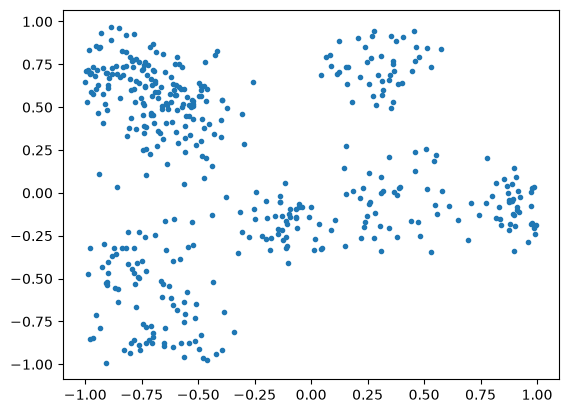

In [2]:
# get the data from csv file, plot it
data = np.genfromtxt("data_kmeans.csv", delimiter=",")
plt.scatter(data[:,0],data[:,1], marker='.')

Q1. Implement `generate_clusters(data, mu)`.

Assign every point in `data` to the closest centroid in `mu`.

Return a 1-D integer array of length `n` (one label per row of `data`). Label `i` means that point was assigned to row `i` of `mu`. If a point is equally close to two centroids, choose the smaller index.

`data` has shape `(n, d)` and `mu` has shape `(k, d)`.


In [3]:
def generate_clusters(data, mu):
    # your code goes here
    k, dim_1 = mu.shape
    n, dim_2 = data.shape
    distances = np.linalg.norm(mu.reshape(k, 1, dim_1) - data.reshape(1, n, dim_2), axis=2)
    closest_idxs = np.argmin(distances, axis=0)
    # indexes = mu[closest_idxs]
    return closest_idxs


Q2. Implement `recompute_centroids(data, labels)`.

`labels` is a 1-D integer array of length `n` with values `0, 1, ..., k-1`, as returned by `generate_clusters`. Every label from `0` through `k-1` appears at least once.

Return a NumPy array of shape `(k, d)`. Row `j` is the mean of the points whose label is `j`.


In [4]:
def recompute_centroids(data, labels):
    # your code goes here
    k = int(np.max(labels) + 1)
    # shape_d = data.shape[0]
    nums = data.shape[1]
    sums = np.zeros((k, nums))
    for d in range(nums):
        sums[:, d] = np.bincount(labels, weights=data[:, d], minlength=k)
    count = np.bincount(labels, minlength=k)[:, np.newaxis]
    return sums / count


Q3. Implement `check_convergence(mu, previous_mu)`.

Return `True` if centroid `i` in `mu` is close to centroid `i` in `previous_mu` for every `i`, and `False` otherwise. Use `np.allclose`: a tiny floating-point difference still counts as the same centroid. Compare centroids by index. A swapped order is not converged.


In [5]:
def check_convergence(mu, previous_mu):
    # your code goes here
    return np.allclose(mu, previous_mu)


Q4. Implement `k_means_clustering(data, k)`.

Return `(mu, labels)`.

* `mu` has shape `(k, d)` and holds the final centroids.
* `labels` is a 1-D integer array of length `n`, using the same labels as `generate_clusters`.

Initialize the centroids to the first `k` rows of `data` (`data[:k]`). Then repeat: assign points with `generate_clusters`, recompute centroids with `recompute_centroids`, and stop when `check_convergence` returns `True`. Also stop after 100 iterations if it has not converged.


In [6]:
def k_means_clustering(data, k):
    mu = data[:k]
    labels = None
    # your code goes here
    # centroids = data[:k]
    for i in range(100):
        labels = generate_clusters(data, mu)
        mu_new = recompute_centroids(data, labels)
        converged = check_convergence(mu_new, mu)
        if (converged):
            mu = mu_new
            break
        mu = mu_new
    return (mu, labels)


Q5. Implement `calc_cohesion(data, labels, mu)`.

Use the cohesion (SSE) definition from the lecture slides. Return that single number.


In [7]:
def calc_cohesion(data, labels, mu):
    # your code goes here
    centroids = mu[labels]
    squared_diffs = (data - centroids) ** 2
    sse = np.sum(squared_diffs)
    return sse


Q6. Implement `calc_separation(data, labels, mu)`.

Use the separation (SSB) definition from the lecture slides. Return that single number.


In [8]:
def calc_separation(data, labels, mu):
    # your code goes here
    grand_mean = np.mean(data, axis=0)
    ssb = 0.0
    for cluster_idx in range(len(mu)):
        n_i = np.sum(labels == cluster_idx)
        square_dist = np.sum((mu[cluster_idx] - grand_mean) ** 2)
        ssb += n_i * square_dist
    return ssb


Q7. Cluster the data using `k_means_clustering` with `k = 5`. Display the clusters using `plt.scatter` and mark each cluster with a different color. Print the cohesion and separation of this clustering using `calc_cohesion` and `calc_separation`.


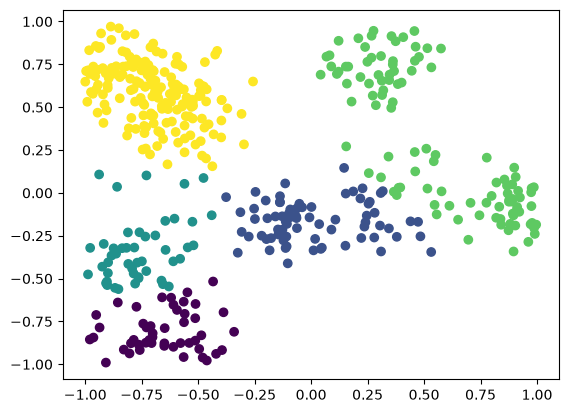

Cohesion: 46.016179996134895
Separation: 226.69632437550317


In [10]:
# your code goes here
mu, labels = k_means_clustering(data, 5)
plt.scatter(data[:,0],data[:,1], c=labels, cmap='viridis')
plt.show()
cohesion = calc_cohesion(data, labels, mu)
separation = calc_separation(data, labels, mu)
print("Cohesion:", cohesion)
print("Separation:", separation)

Q8. Find the best k for this dataset by plotting SSE vs k for k = 1 through 10. SSE for a clustering is the `calc_cohesion` of that clustering. Based on your plot, which value of k would you choose and why? (Answer as a comment.)


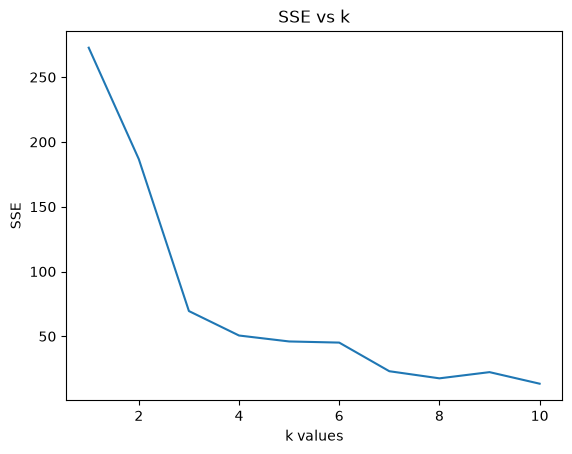

In [46]:
# your code goes here
list_k = list()
list_sse = list()
for i in range(1, 11):
    list_k.append(i)
    cur_mu, cur_labels = k_means_clustering(data, i)
    cur_cohesion = calc_cohesion(data, cur_labels, cur_mu)
    list_sse.append(cur_cohesion)

plt.plot(list_k, list_sse)
plt.xlabel("k values")
plt.ylabel("SSE")
plt.title("SSE vs k")
plt.show()
    
# The best k for this dataset is 3 because that is where the "elbow" of the graph occurs and where you get diminishing returns for decrease
# in SSE versus an increase in k. 

## Part 2: Implement DBSCAN

For this part you'll be implementing DBSCAN, one of the most popular density-based clustering algorithms.


<class 'numpy.ndarray'>


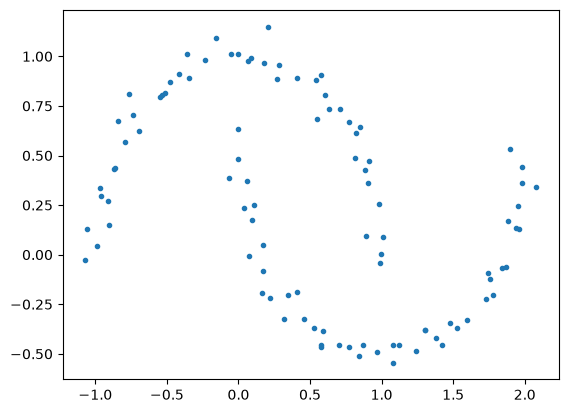

In [11]:
# get data from text file
data = np.genfromtxt("data_dbscan.csv", delimiter=",")
plt.scatter(data[:,0],data[:,1], marker='.')
print(type(data))


Q9. Run your `k_means_clustering` with `k = 2` on this dataset and display the output clusters. Make sure different clusters are marked with different colors. What do you observe? (Answer as a comment.)


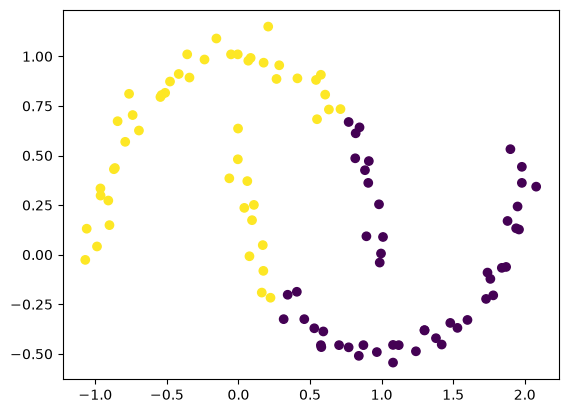

In [12]:
# your code goes here
mu, labels = k_means_clustering(data, 2)
plt.scatter(data[:,0],data[:,1], c=labels, cmap='viridis')
plt.show()

# The clusters are supposed to be two distinct U-shapes. However, the k-means clustering seems to have combined parts of one cluster with 
# another. 

Q10. Implement `region_query(data, index, eps)`.

Return the indices of every row of `data` within Euclidean distance `eps` of `data[index]`, including `index` itself. A point at distance exactly `eps` is a neighbor.


In [17]:
def region_query(data, index, eps):
    # your code goes here
    point = data[index]
    distances = np.linalg.norm(data - point, axis=1)
    neighbors = np.where(distances <= eps)[0]
    return neighbors


Q11. Implement `dbscan(data, eps, min_pts)`.

There is a pseudocode version of DBSCAN on [Wikipedia](https://en.wikipedia.org/wiki/DBSCAN#Algorithm) that you are welcome to follow. Use `region_query` to find neighbors.

(If you are not familiar with the `continue` statement, look [here](https://www.tutorialspoint.com/python/python_loop_control.htm) for what it does. It may not do what you think.)

Return a 1-D integer array of length `n`.

* Noise points are labeled `-1`.
* Every other label is a nonnegative integer. Points in the same cluster share a label, and different clusters use different labels. The particular numbers you choose for the clusters do not matter.

A point is a core point when its neighborhood, including itself, contains at least `min_pts` points. A border point is not a core point, but it is within `eps` of a core point: assign it to that core point's cluster. Expand a cluster through core points, so points that are density-connected end up in the same cluster even when the two ends are more than `eps` apart.


In [18]:
def dbscan(data, eps, min_pts):
    # your code goes here
    c_num = 0
    labels = [0] * len(data)
    for i in range(len(data)):
        if (labels[i] != 0):
            continue
        neighbors = region_query(data, i, eps)
        if (len(neighbors) < min_pts):
            labels[i] = -1
            continue
        c_num += 1
        labels[i] = c_num
        seedset = list(neighbors)
        if i in seedset:
            seedset.remove(i)

        idx = 0
        while idx < len(seedset):
            s = seedset[idx]
            if (labels[s] == -1):
                labels[s] = c_num
            if (labels[s] != 0):
                idx += 1
                continue
            labels[s] = c_num
            new_neighbors = region_query(data, s, eps)
            if (len(new_neighbors) >= min_pts):
                for n in new_neighbors:
                    if n not in seedset and n != i:
                        seedset.append(n)
            idx += 1
    return labels


Q12. Run `dbscan` on this dataset with `eps = 0.28` and `min_pts = 8`. Plot the resulting clusters with each cluster, and the noise, indicated by different colors.


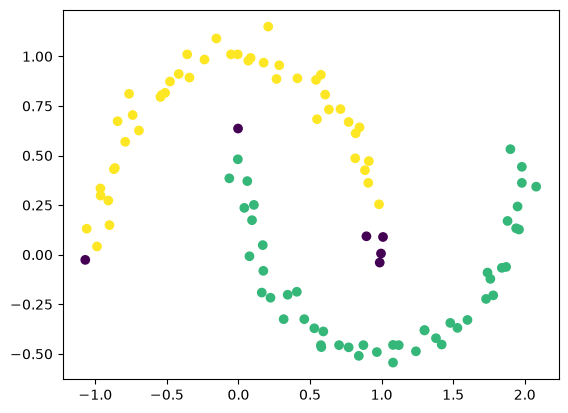

In [19]:
# your code goes here
labels = dbscan(data, 0.28, 8)
plt.scatter(data[:,0],data[:,1], c=labels, cmap='viridis')
plt.show()

# Cluster 1 is yellow, cluster 2 is green, and the noise is indicated by dark purple points

## Part 3: Clustering with scikit-learn and scipy


#### Data

For this part of the assigment you'll be working with the Epileptic Seizure Recognition Data Set developed at Rochester Institute of Technology. In this data set each row is a sample of the EEG recording at a different point in time. The dataset contains 179 columns, the first 178 are the EEG features while the last column represents the label y {1, 2, 3, 4, 5}. All subjects falling in classes 2, 3, 4, and 5 are subjects who did not have epileptic seizure. Only subjects in class 1 have an epileptic seizure. The class labels will not be used for our *unsupervised* clustering - they will just be used for plotting the data. The only change that was made to the original dataset was removing the first column, which contained the row indexes. You can find additional information about the dataset [here](https://archive.ics.uci.edu/ml/datasets/Epileptic+Seizure+Recognition).


In [5]:
# Reading the Epileptic Seizure Data Set
dataset = pd.read_csv("data_seizure_edited.csv", header = 0)
print(dataset.shape)

#split the dataset into features and labels
labels = dataset['y']
raw_data = dataset.drop('y', axis = 1)

dataset.head()

(11500, 179)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,135,190,229,223,192,125,55,-9,-33,-38,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,386,382,356,331,320,315,307,272,244,232,...,164,150,146,152,157,156,154,143,129,1
2,-32,-39,-47,-37,-32,-36,-57,-73,-85,-94,...,57,64,48,19,-12,-30,-35,-35,-36,5
3,-105,-101,-96,-92,-89,-95,-102,-100,-87,-79,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,-9,-65,-98,-102,-78,-48,-16,0,-21,-59,...,4,2,-12,-32,-41,-65,-83,-89,-73,5


#### Data scaling & dimensionality reduction with PCA
Both K-means and DBSCAN break down in high dimensions, as distance (and thus density) become less meaningful in high dimensions. So, before we run either of these clustering algorithms, we want to reduce the dimensionality of our dataset. Recall that it is critical to scale your data prior to running PCA. 


Q13. 
* Use `sklearn.preprocessing.StandardScaler` to standardize the dataset’s features (mean = 0 and variance = 1). Only standardize the the features, not the class labels! This will be required for running the principal component analysis (PCA) dimensionality reduction. Note that `StandardScaler` returns a numpy array.
* Use `sklearn.decomposition.PCA` to perform PCA on the data.
* Set `n_components` to 0.95 and `svd_solver` to 'full', so that the PCA will reduce the number of dimensions to however many are necessary to retain 95% of the variance. 
* Use `fit_transform` to perform the dimensionality reduction. 
* Note that `fit_transform` returns a numpy array. Put your transformed data back into a Pandas DataFrame by doing something like this (subsitute your variable names): `data = DataFrame(pca_data)`.
* Show the head of the resulting DataFrame (and make sure the dimensionality has actually been reduced).


In [ ]:
# your code goes here

Q14. You are provided code here to plot the data. This code randomly samples 300 rows from the entire dataset, then uses `sklearn.manifold.MDS` to project the data onto two dimensions, and plots it on a scatter plot. The points will be marked with appropriate colors based on their labels. This is the only time labels will be used.
* Pass your dataset (that has been reduced in dimensions from Q13) and the labels into this scatter function. Verify that the plot looks like 2 clusters: an inner cluster (non-seizure patients, labels 2-5, will be blue/green/yellow), and an outer cluster (seizure patients, label 1, will be purple).


In [ ]:
# do not change this plotting function!
def scatter(data, labels, numPoints = 300):

    numEntries = data.shape[0]
    start = random.randint(0, numEntries - numPoints)
    end = start + numPoints
    data = data.iloc[start:end, :]
    labels = labels.iloc[start:end]
    
    mds = MDS(n_components=2)
    mds_data = mds.fit_transform(data)
    plt.scatter(mds_data[:, 0], mds_data[:, 1], c=labels, s=50)
    plt.show()

# your code goes here

#### Clustering with DBSCAN


Recall that for DBSCAN, we need to select an Eps and a MinPts. If we choose MinPts to be 4, then Eps can be selected by plotting the distance of every point to its 4th nearest neighbor and finding the "bend" in the graph. 

Q15. Find the optimal Eps for this dataset by plotting the distances of every point to its 4th nearest neighbor.
* Use `sklearn.neighbors.NearestNeighbors` with `n_neighbors=4`. Call `fit` on your data.
* Use the `kneighbors` method to find the distance of each point to its 4th nearest neighbor. Note that `kneighbors` returns two values. The first return value is a matrix of distances from each point to its k nearest neighbors. 

* Sklearn considers the distance from the point to itself as the closest neighbor (a distance of 0), then if the point is a distance of 2.5 away from its second nearest neighbor, a distance of 3.7 away from its third nearest neighbor, and a distance of 4.2 away from its fourth nearest neighbor, the row in the distance matrix for this point would look like: `[0, 2.5, 3.7, 4.2]`, indicating that 4.2 is the distance from this point to it's 4th nearest neighbor. 

* Plot the distance of every point to its 4th nearest neighbor. Be sure to sort the distances before you plot them. You can use `plt.plot(distances)` then `plt.show()` to plot them. 
* Use the plot to determine the best Eps for this dataset (just eyeball it).


In [ ]:
# your code goes here

Q16. 
* Using MinPts=4 and Eps=the distance you determined from Q15, cluster the data using `sklearn.cluster.DBSCAN`. Call `fit_predict` on your data and store the return value (the predicted cluster label for each data point). Note that the returned type is a numpy array. 
* Use the provided `scatter` function (Q14) to plot the resulting clusters. You will need to convert the numpy array of predicted labels to a `Series` in order to pass it in to `scatter`.


In [ ]:
# your code goes here

#### Clustering with K-means


Q17. 
* Use `sklearn.cluster.KMeans` to cluster this data using k-means. Try values of k from 2 to 5. You will need to call `fit_predict` on your data and store the return value (the predicted cluster label for each data point). Note that the returned type is a numpy array. 
* Use `sklearn.metrics.silhouette_score` to determine an appropriate number of clusters for this dataset. 
* Use the provided `scatter` function (Q14) to plot the clustering that resulted in the best silhouette score. Note that you will need to cast the predicted cluster labels (a numpy array) to a Series in order to pass it in to `scatter`.


In [ ]:
# your code goes here

Q18. What do you observe about the results of DBSCAN vs the results of k-means? Answer as a comment.


In [ ]:
'''
Your answer goes here.
'''

#### Hierarchical Clustering


For hierarchical clustering (Q19 and Q20), you'll work with a sample of only 115 datapoints. The function to downsample the dataset is provided here for you.


In [ ]:
# Do not change the code in this cell
# stratified sampling of the data
def downsample_data(data, labels):
    downData = None
    downLabels = None

    kfold = StratifiedKFold(n_splits = 100, shuffle = False)
    for throwAway_index, subsample_index in kfold.split(data, labels):
        downData = data.iloc[subsample_index]
        downLabels = labels.iloc[subsample_index]
        break
    
    print(downData.shape)
    return downData

Q19. Use Scipy's hierarchical clustering (`scipy.cluster.hierarchy`) to cluster the data using different linkage methods. **Make sure you are using a down-sampled dataset by passing your dataset into the provided downsample_data() function.**

* Try all of these linkage methods: `single`, `complete`, `average`, `centroid`, `ward`
* Note that the return value of the clustering is a linkage matrix (a cophenetic distance matrix)

* Calculate the CPCC of each linkage method to determine which method worked best. Use `scipy.cluster.hierarchy.cophenet` for this. You'll pass in the linkage matrix from the clustering, and a proximity matrix that contains the actual distances between each point, which you can get by using `scipy.spatial.distance.pdist`. 


In [ ]:
# Make sure to pass your dataset into downsample_data() 
# and use the resulting smaller dataset for hierachical clustering

# Pass the down-sampled dataset into pdist to get your proximity matrix for calculating CPCC
proximity_matrix = pdist(sampled_dataset_goes_here)

# the rest of your code goes here

Q20. Using the best linkage method that you found in Q19, plot the dendrogram with `scipy.cluster.hierarchy.dendrogram`. (The labels on the x-axis will be too small to read - that is ok!)


In [ ]:
# your code goes here

#### Anomaly Detection (AD)

Anomaly detection (AD) algorithms can be broadly classified into 3 classes:
- Supervised AD (labels available for both normal data and anomalies)
- Semi-supervised AD, also called Novelty Detection (only normal data is available to train on)
- Unsupervised AD, also called Outlier Detection (no labels are provided)

In this part you'll experiment with 4 datasets and compare 4 different outlier detection (Unsupervised AD) methods.


In [4]:
# loading the datasets
filenames = ['data1.csv', 'data2.csv', 'data3.csv', 'data4.csv']
datasets = [np.loadtxt(fname, delimiter=',') for fname in filenames]
for fname, data in zip(filenames, datasets):
    print (fname, data.shape)

data1.csv (445, 2)
data2.csv (314, 2)
data3.csv (419, 2)
data4.csv (441, 2)


Q21. Detect the outliers in all 4 datasets using the following algorithms:
- `sklearn.covariance.EllipticEnvelope` - a statistical-based AD method
- `sklearn.ensemble.IsolationForest` - an isolation-based AD method
- `sklearn.neighbors.LocalOutlierFactor` - a density-based AD method
- `sklearn.svm.OneClassSVM` - a model-based AD method

Create scatterplots that show the outliers detected in each dataset with each method. (16 plots in total.)

The following plotting function is provided for you. You should pass in a list of y_pred values corresponding to all 16 of your plots. 

In order for this plotting function to work correctly, the order of your list should be: EllipticEnvelope on dataset1, IsolationForest on dataset1, LocalOutlierFactor on dataset1, OneClassSVM on dataset1, EllipticEnvelope on ds2, IsolationForest on ds2, LocalOutlierFactor on ds2, OneClassSVM on ds2, EE on ds3, IF on ds3, LOF on ds3, SVM on ds3, EE on ds4, IF on ds4, LOF on ds4, SVM on ds4.


In [ ]:
# Do not change the code in this cell!
# Create all 16 anomaly detection plots
def plot_all(y_preds):
    
    print("len(y_preds):", len(y_preds))
    
    names = ['Robust Covariance', 'Isolation Forest', 'Local Outlier Factor', 'One-Class SVM']
    plt.figure(figsize=(len(names) * 2 + 3, 12.5))
    plt.subplots_adjust(left=.02, right=.98, bottom=.001, top=.96, wspace=.05, hspace=.01)
    plot_num = 1
    
    for i_dataset in range(len(datasets)):
        for j_algorithm in range(len(names)):
            
            plt.subplot(len(datasets), len(names), plot_num)
            if i_dataset == 0:
                plt.title(names[j_algorithm], size=18)

            colors = np.array(['#377eb8', '#ff7f00'])
            plt.scatter(datasets[i_dataset][:, 0], datasets[i_dataset][:, 1], 
                        s=10, color=colors[(y_preds[plot_num-1] + 1) // 2])

            plt.xlim(-7, 7)
            plt.ylim(-7, 7)
            plt.xticks(())
            plt.yticks(())
            
            plot_num += 1

    plt.show()

Directions:
* Use a `contamination` (or `nu` for `OneClassSVM`) of 0.25.
* For the `OneClassSVM` use `rbf` kernel.
* NOTE: To preform AD in an unsupervised way, you will pass the same dataset into `fit` and `predict.`

Some code is provided here to get you started.


In [ ]:
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM


outliers_fraction = 0.25

#this will be your list of 16 plots
y_pred_list = list()

#for each of the 4 datasets
for X in datasets:
    
    #apply EllipticEnvelope AD
    #append resulting y_pred to y_pred_list
    
    #apply IsolationForest AD
    #append resulting y_pred to y_pred_list
    
    #apply LocalOutlierFactor AD
    #append resulting y_pred to y_pred_list

    #apply OneClassSVM AD
    #append resulting y_pred to y_pred_list

 

plot_all(y_pred_list)